# Phase 1: AI-Driven Multimodal Brain Tumour Project — Dataset Audit

This notebook performs a comprehensive inventory and data quality audit across all multimodal brain tumour datasets:
- **MRI Dataset**: Image counts, class distribution, corrupt image detection, perceptual hash duplicate check, width/height resolution statistics.
- **Gene Expression Datasets**:
  1. TCGA-GBM (Glioblastoma Multiforme)
  2. TCGA-LGG (Lower Grade Glioma)
  3. GEO GSE43290 (Meningioma + normal meninges)
  4. GEO GSE93825 (Pituitary ACTH adenomas)
  5. CGGA (Chinese Glioma Genome Atlas mRNAseq 693 samples + Clinical Data)


In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("C:/Research_Project/Brain_Tumor_Project")
from src.mri_preprocessing import scan_mri_dataset, find_duplicate_images
from src.gene_preprocessing import (
    load_tcga_data, load_geo_series_matrix, 
    load_cgga_expression, load_cgga_clinical
)

sns.set_theme(style="whitegrid")
%matplotlib inline


## 1. MRI Dataset Audit

In [2]:
mri_train_dir = "C:/Research_Project/Brain_Tumor_Multimodal_Datasets/MRI/Training"
mri_test_dir = "C:/Research_Project/Brain_Tumor_Multimodal_Datasets/MRI/Testing"

df_train = scan_mri_dataset(mri_train_dir)
df_train['split'] = 'Training'

df_test = scan_mri_dataset(mri_test_dir)
df_test['split'] = 'Testing'

df_mri = pd.concat([df_train, df_test], ignore_index=True)
print(f"Total Scanned MRI Images: {len(df_mri)}")
print(f"Corrupted Images: {df_mri['is_corrupted'].sum()}")

# Class distribution
print("\n--- MRI Class Distribution ---")
print(pd.crosstab(df_mri['class'], df_mri['split'], margins=True))


Total Scanned MRI Images: 7200
Corrupted Images: 0

--- MRI Class Distribution ---
split       Testing  Training   All
class                              
glioma          400      1400  1800
meningioma      400      1400  1800
notumor         400      1400  1800
pituitary       400      1400  1800
All            1600      5600  7200


In [3]:
# Display saved MRI Inventory CSV
inv_df = pd.read_csv("C:/Research_Project/Brain_Tumor_Project/results/reports/MRI_Dataset_Inventory.csv")
inv_df.head()


,filename,path,class,file_size_bytes,width,height,aspect_ratio,mode,is_corrupted,split
0,Tr-gl_1.jpg,C:\Research_Project\Brain_Tumor_Multimodal_Dat...,glioma,20892,512,512,1.0,L,False,Training
1,Tr-gl_10.jpg,C:\Research_Project\Brain_Tumor_Multimodal_Dat...,glioma,26456,512,512,1.0,L,False,Training
2,Tr-gl_100.jpg,C:\Research_Project\Brain_Tumor_Multimodal_Dat...,glioma,20150,512,512,1.0,L,False,Training
3,Tr-gl_1000.jpg,C:\Research_Project\Brain_Tumor_Multimodal_Dat...,glioma,24892,512,512,1.0,L,False,Training
4,Tr-gl_1001.jpg,C:\Research_Project\Brain_Tumor_Multimodal_Dat...,glioma,14756,512,512,1.0,L,False,Training


## 2. Gene Expression Dataset Audit

In [4]:
gene_inv = pd.read_csv("C:/Research_Project/Brain_Tumor_Project/results/reports/Gene_Dataset_Inventory.csv")
gene_inv


,dataset,samples,genes,missing_values,missing_pct,duplicate_genes,min_val,max_val,mean_val
0,TCGA-GBM,172,20530,0,0.0,0,0.000000,1.996910e+01,6.556822
1,TCGA-LGG,530,20530,0,0.0,0,0.000000,2.128460e+01,6.504295
2,GSE43290,51,22283,0,0.0,0,3.187816,1.477471e+01,6.420306
3,GSE93825,40,20818,0,0.0,0,-63.147770,5.772909e+04,2851.569972
4,CGGA,693,23987,0,0.0,0,0.000000,1.426661e+07,98.166202


## 3. Visualizations

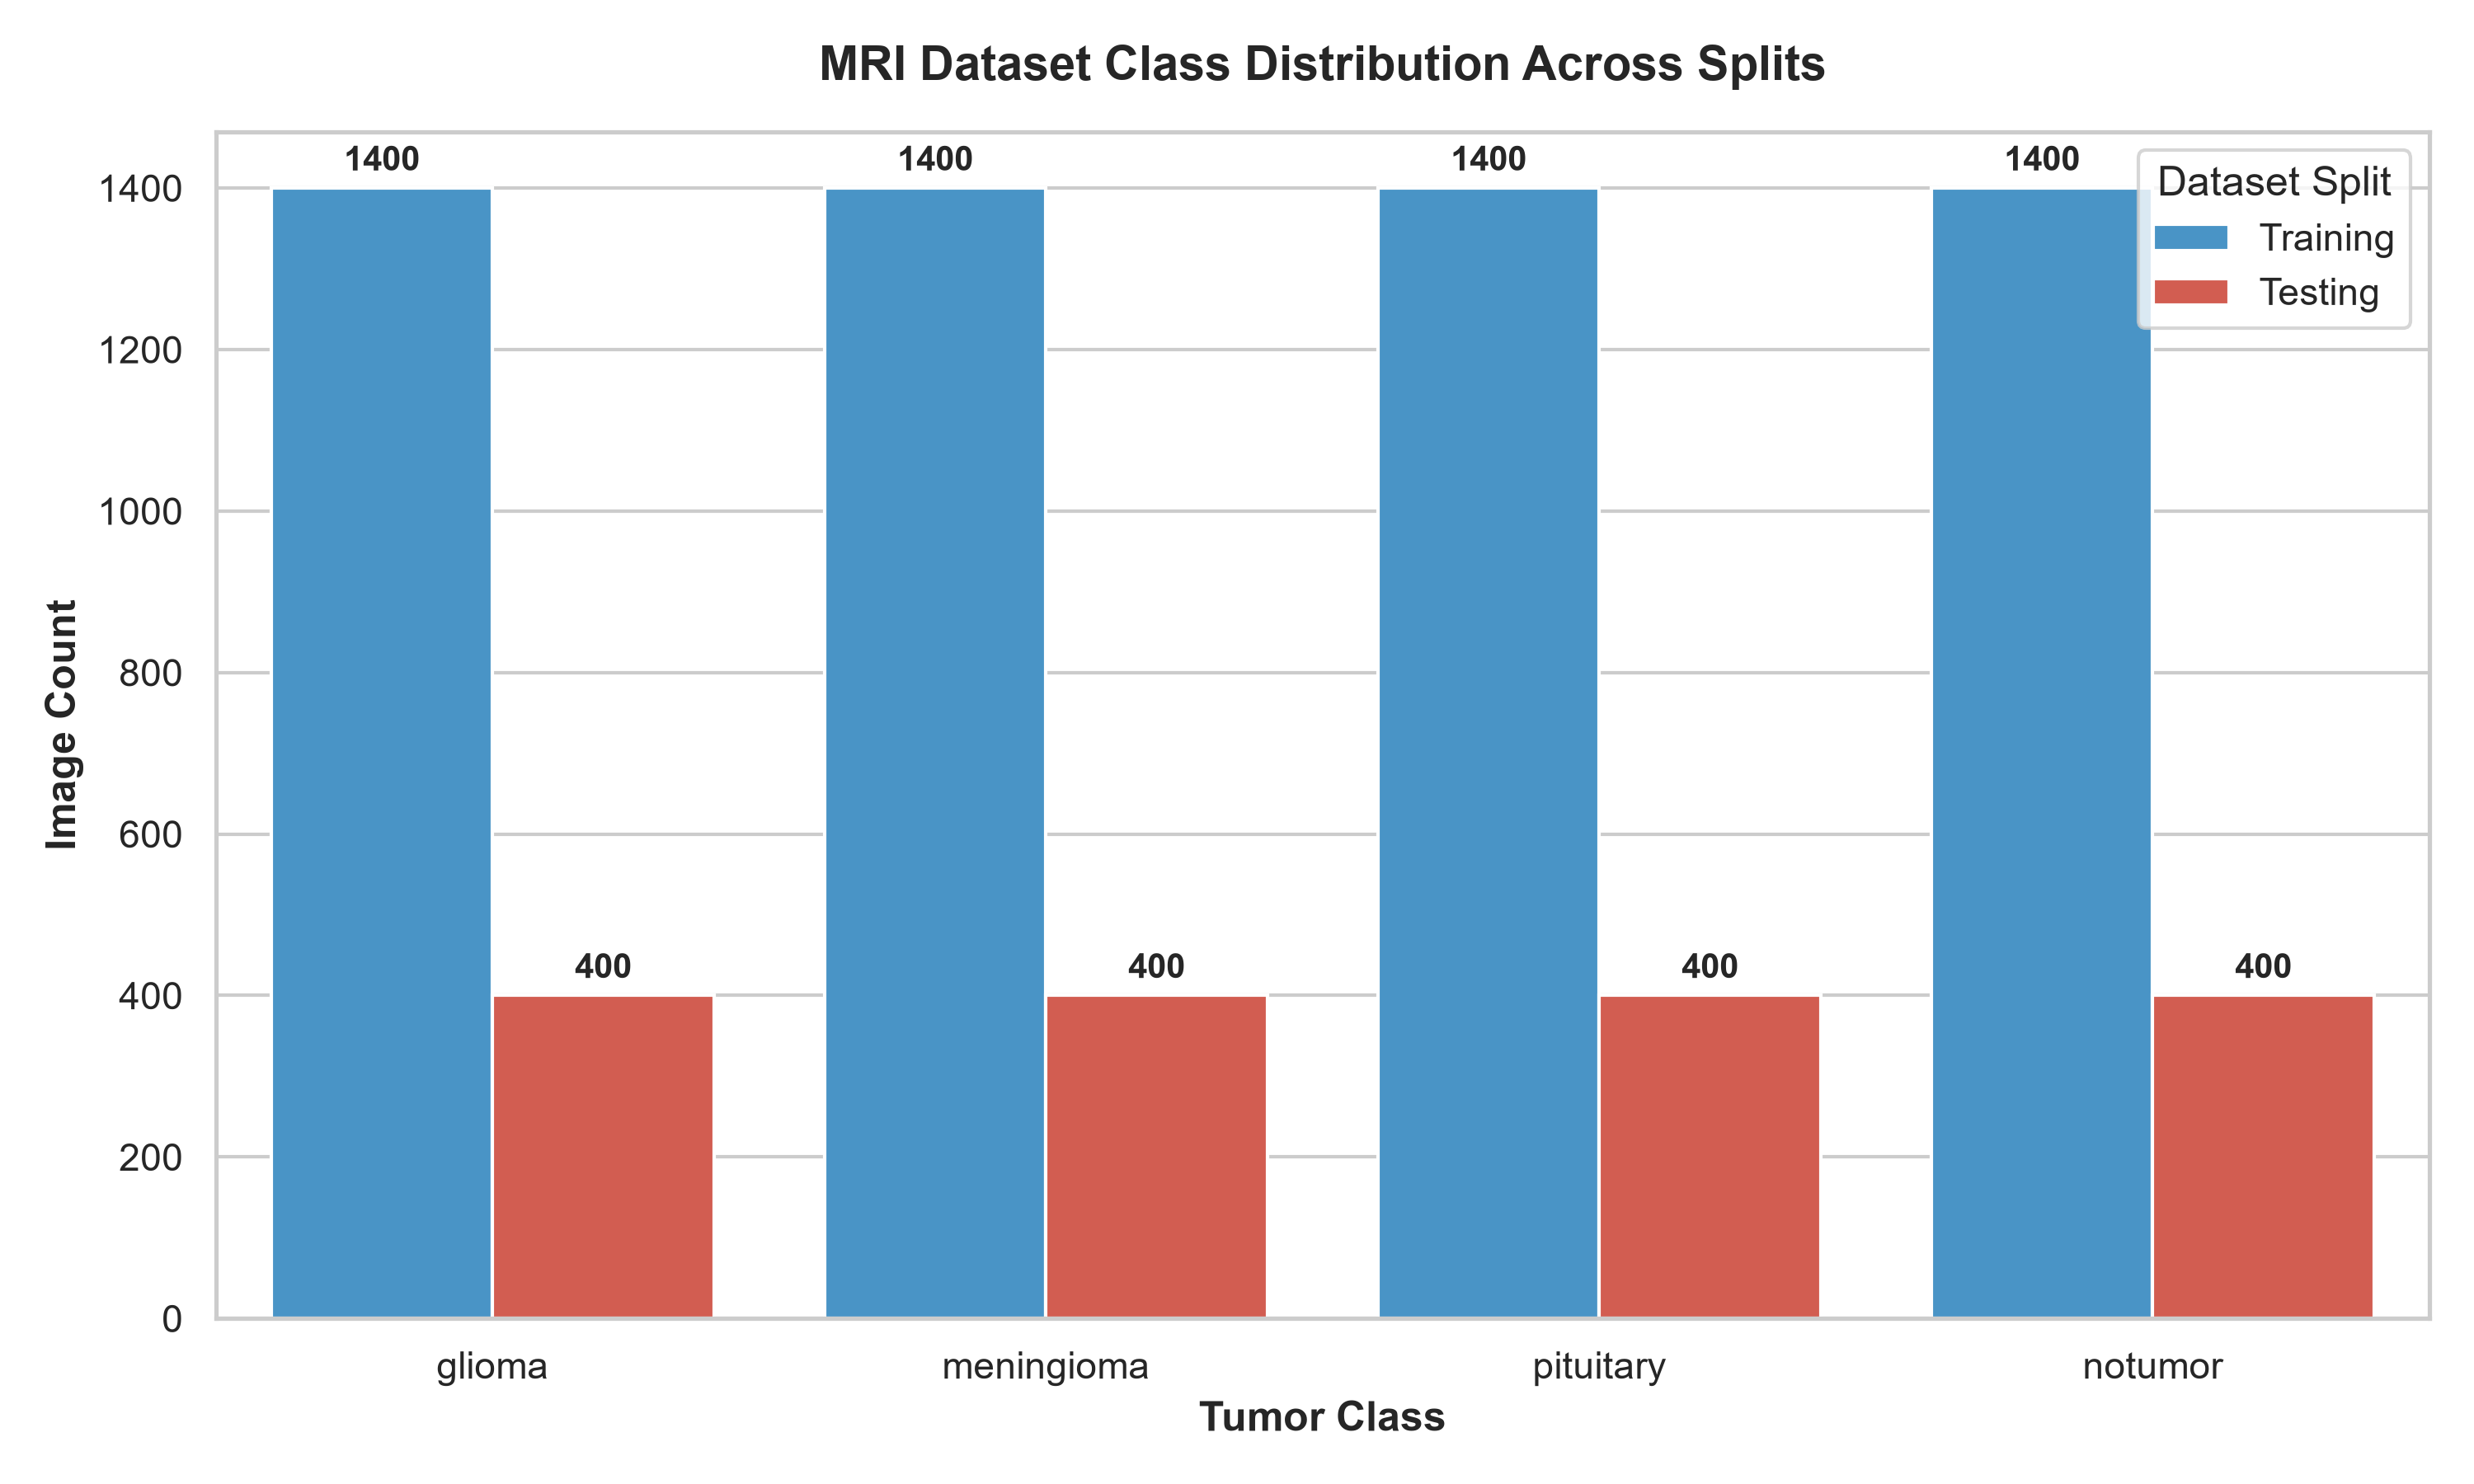

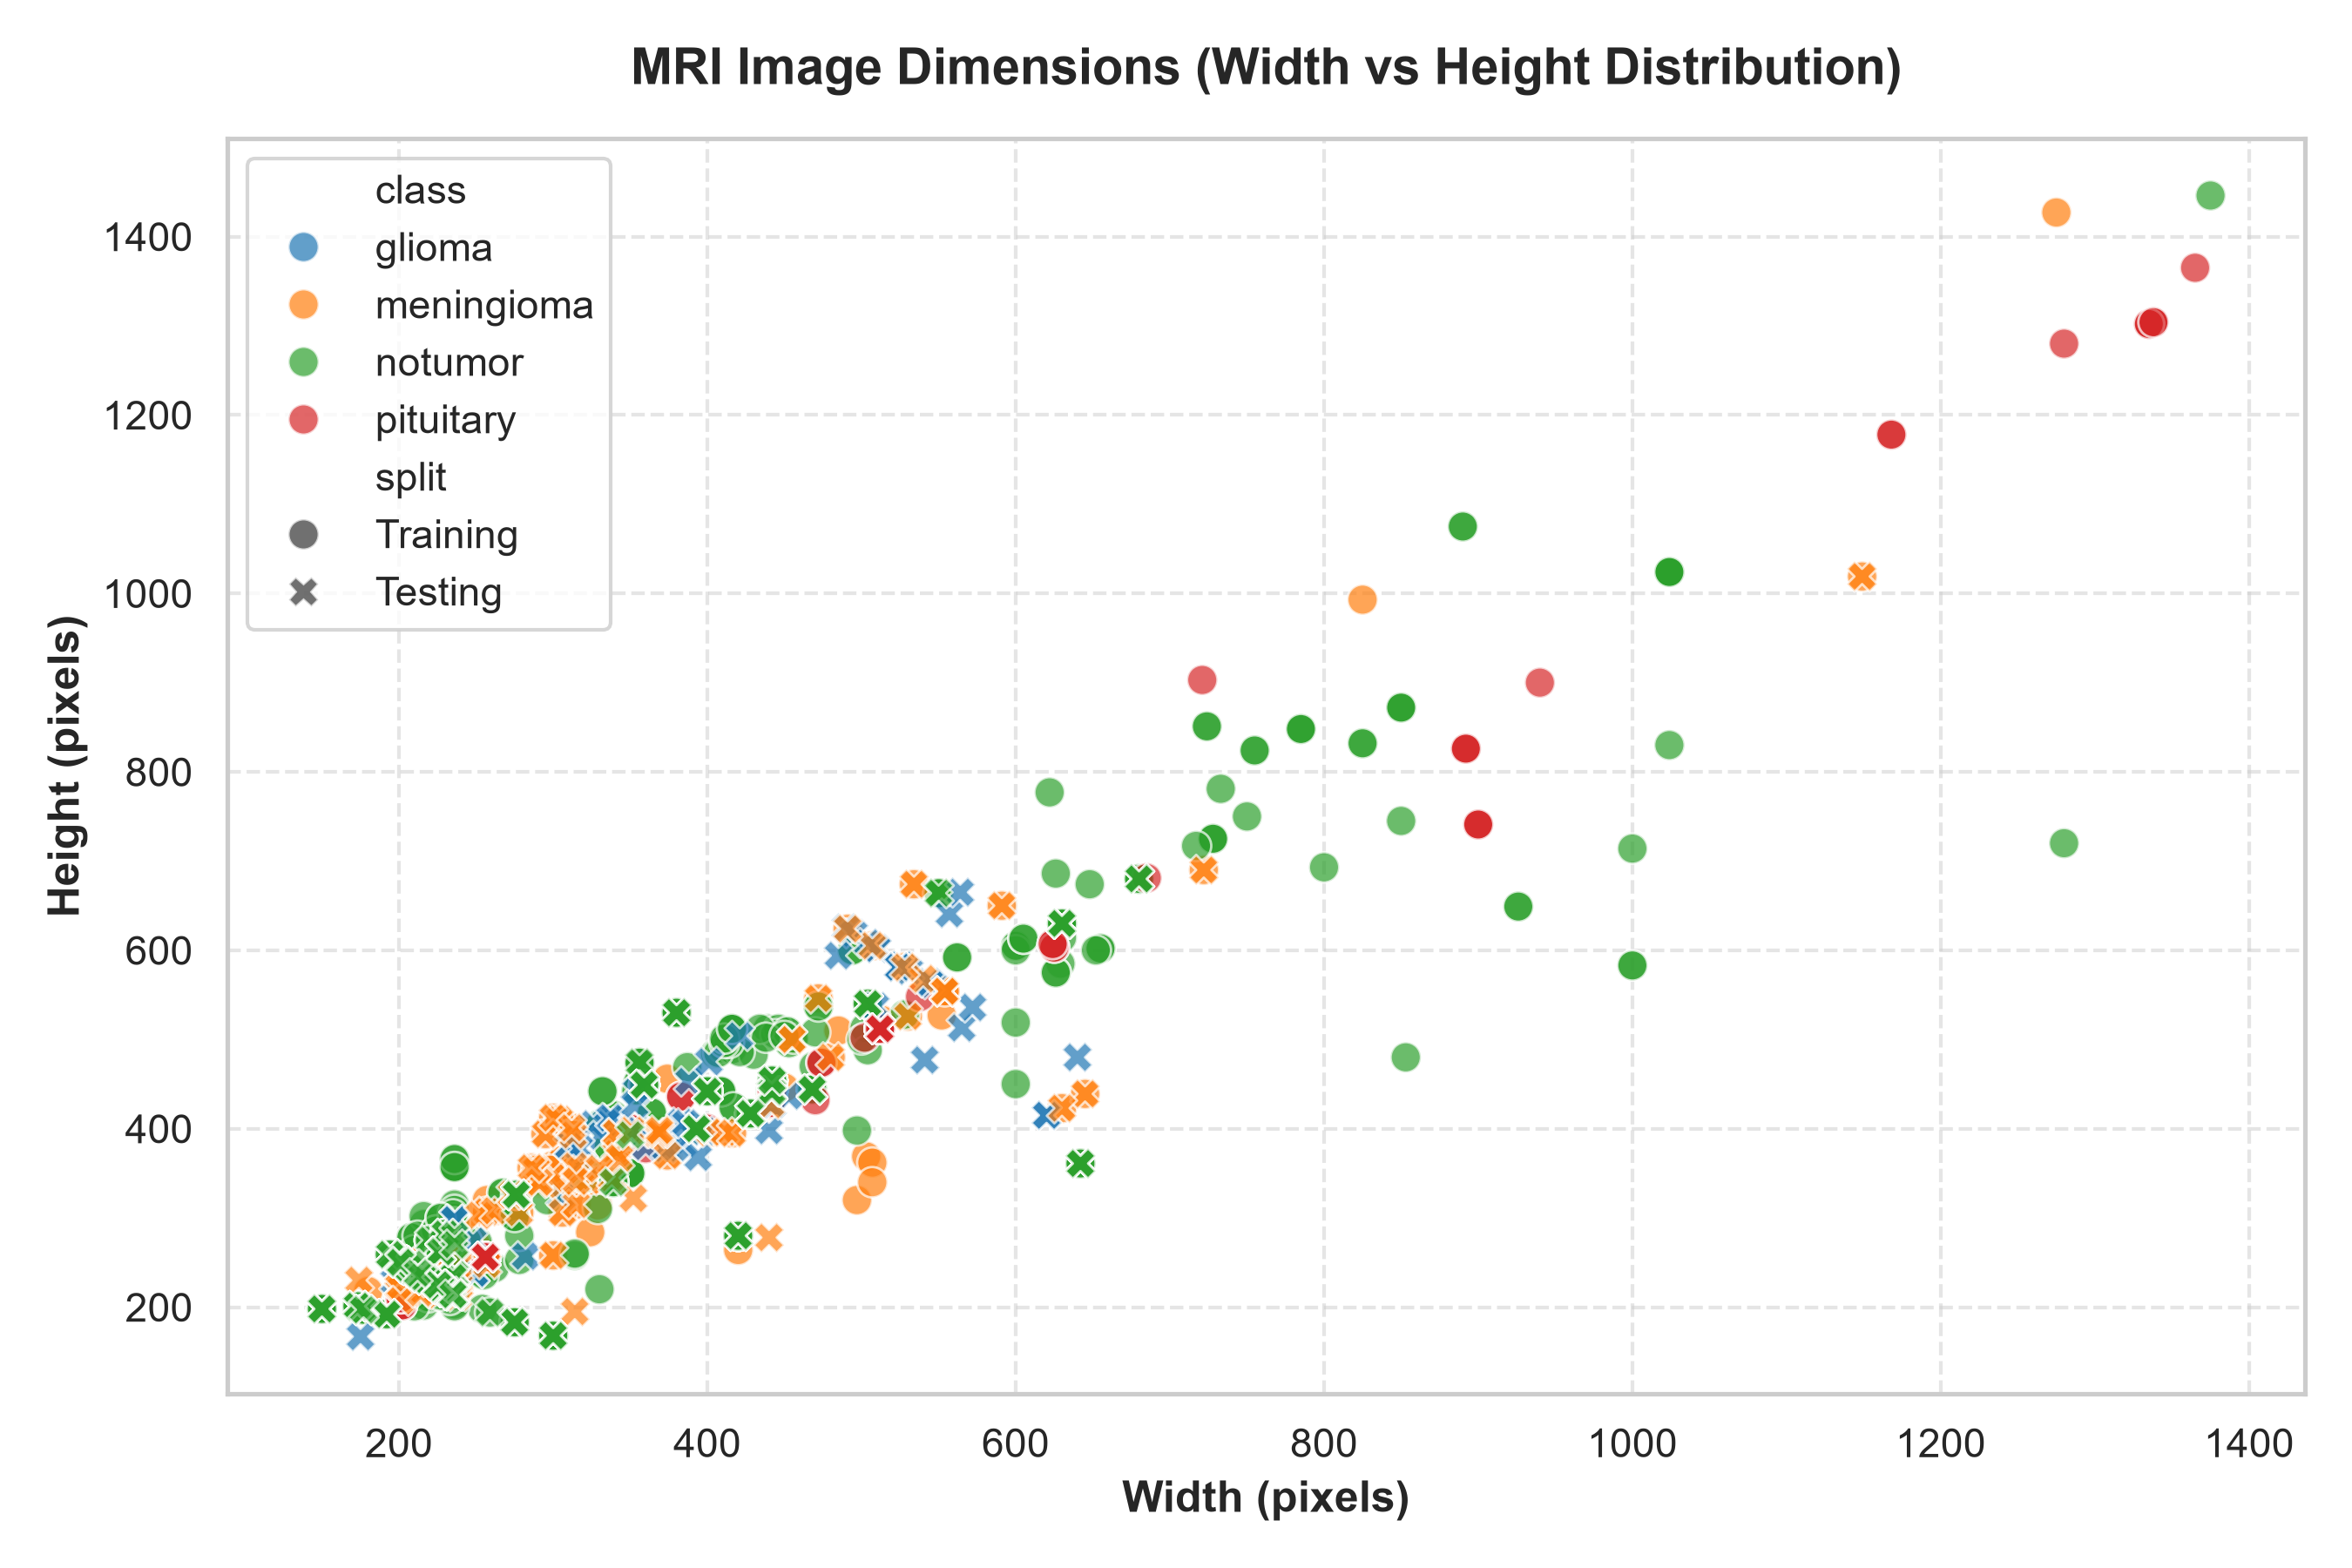

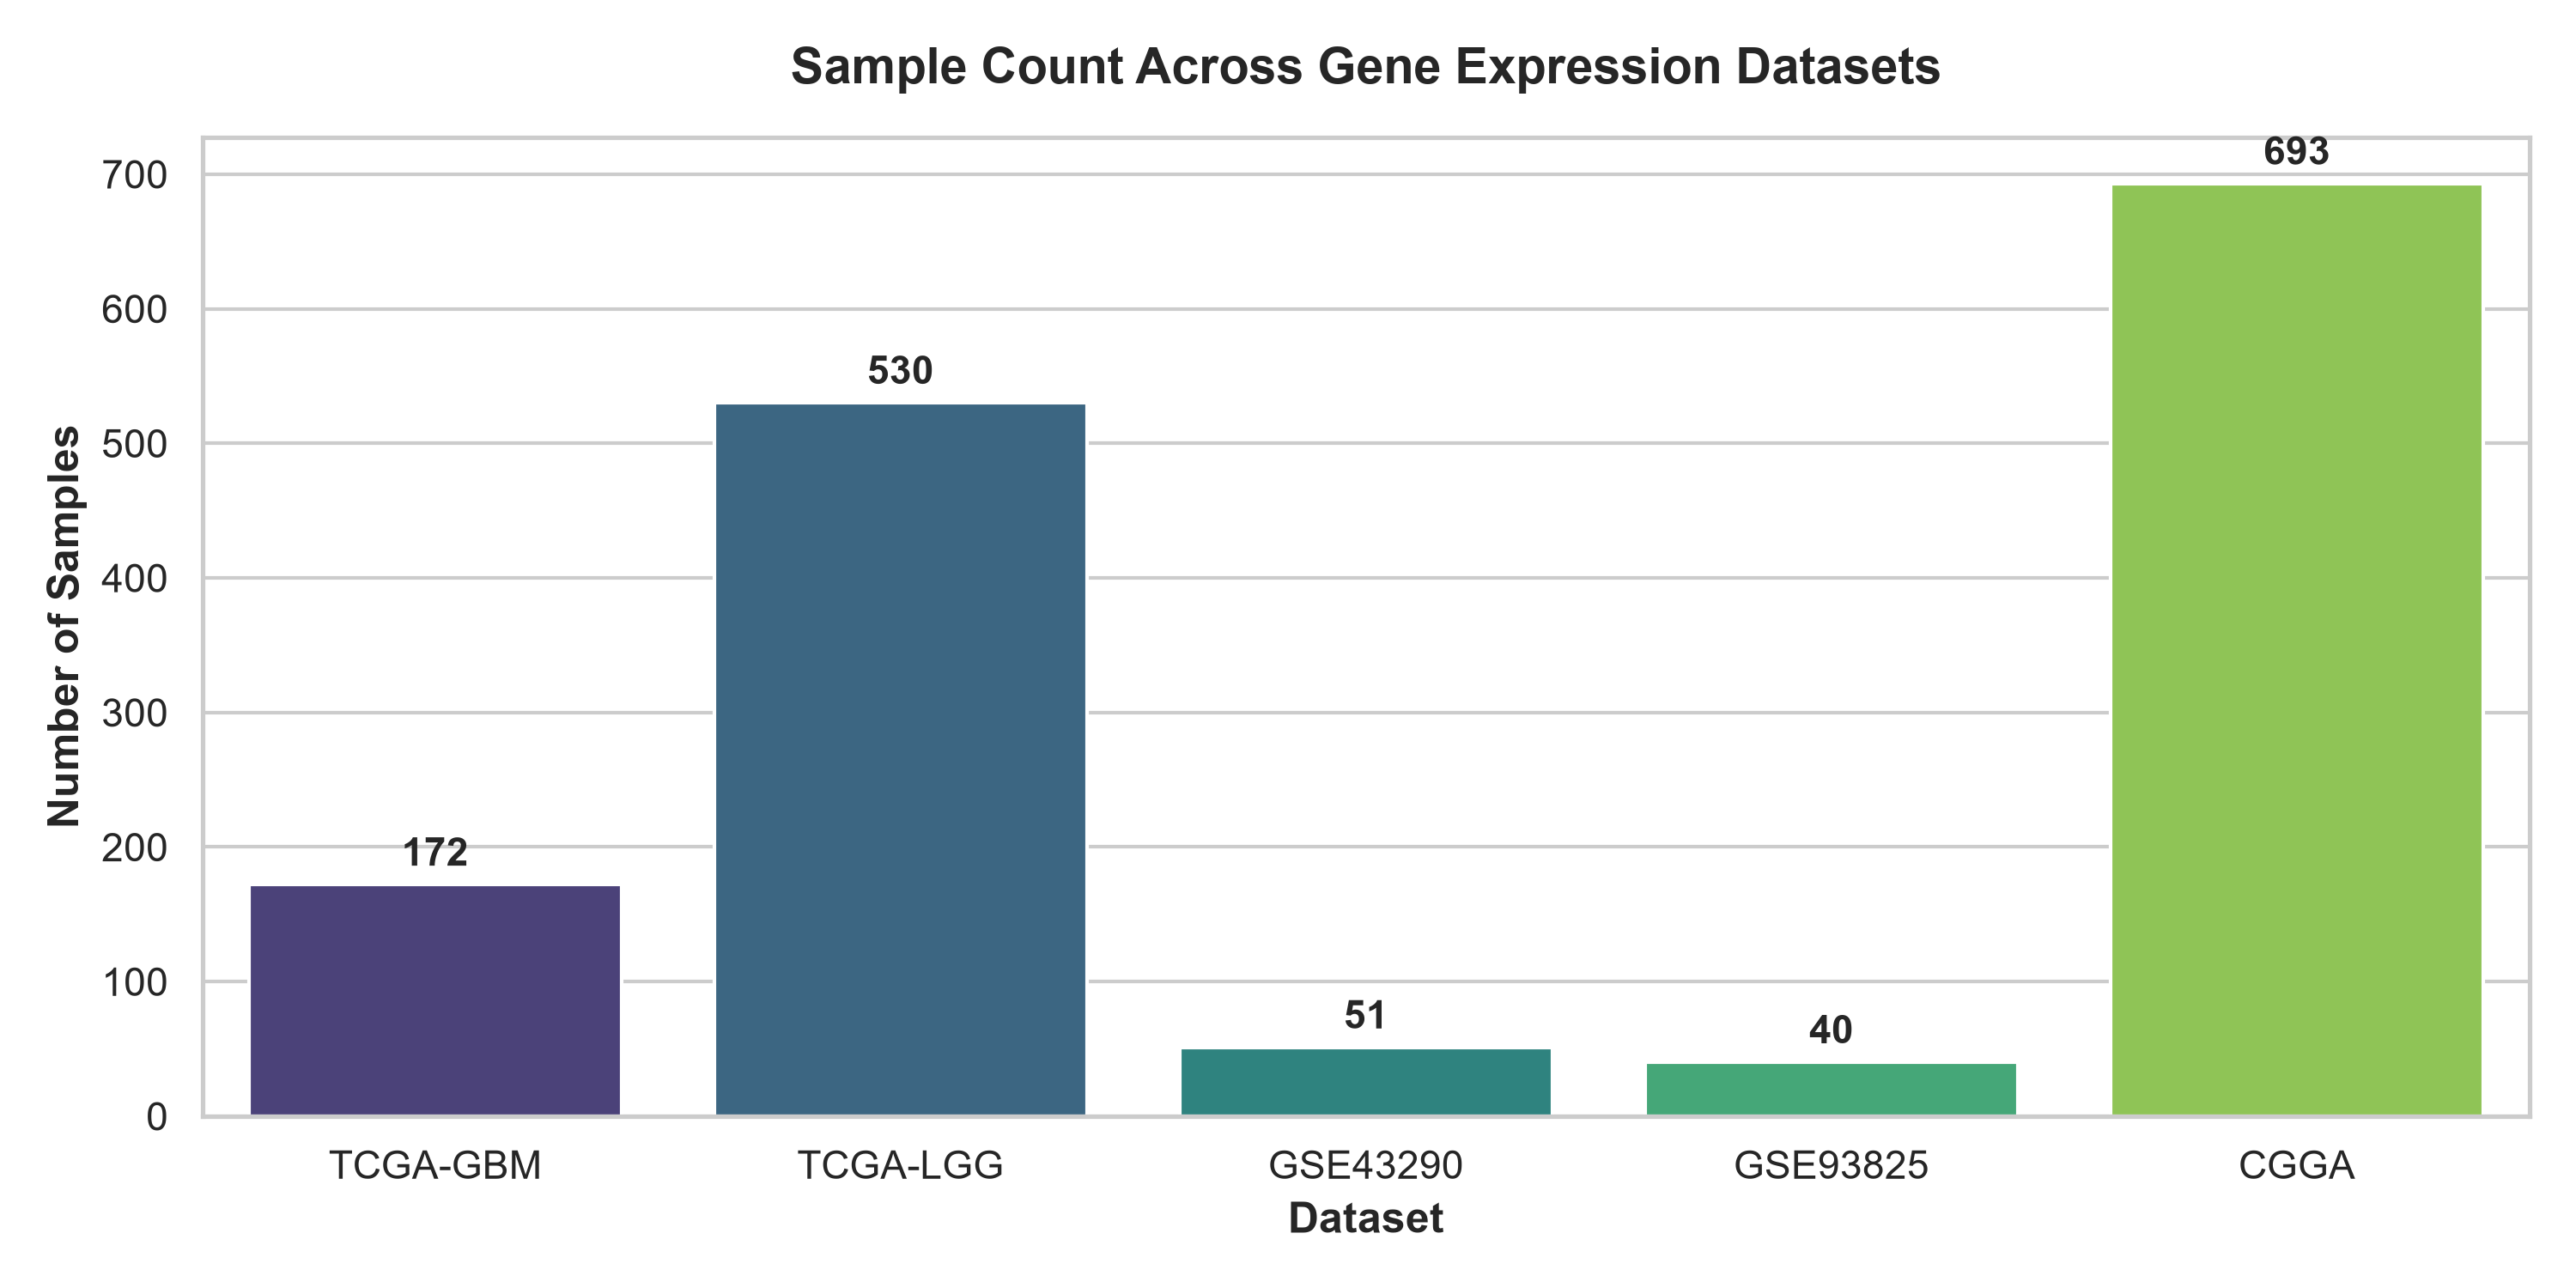

In [5]:
from IPython.display import Image, display
display(Image(filename="C:/Research_Project/Brain_Tumor_Project/results/figures/mri_class_distribution.png"))
display(Image(filename="C:/Research_Project/Brain_Tumor_Project/results/figures/mri_resolution_distribution.png"))
display(Image(filename="C:/Research_Project/Brain_Tumor_Project/results/figures/gene_dataset_samples.png"))
